# Partie 3 — Détection de la pneumonie sur radiographie thoracique
### Mémoire « Mieux détecter pour mieux soigner » — IPSSI

Ce notebook produit **vos résultats réels** (métriques + figures) pour la Partie 3 du mémoire.
Il est conçu pour **Google Colab** (GPU gratuit). Pour l'activer : `Exécution > Modifier le type d'exécution > GPU (T4)`.

**Pipeline complet :** téléchargement du dataset → re-split stratifié → prétraitement + augmentation → ResNet50 (transfer learning) → évaluation (accuracy, sensibilité, spécificité, F1, AUC) → matrice de confusion → courbe ROC → Grad-CAM.

À la fin, un fichier `metrics.json` et 4 figures PNG sont enregistrés : copiez les chiffres dans le tableau 3.3 et insérez les figures dans le mémoire.

## 1. Installation et imports

In [1]:
# Sur Colab, tensorflow et la plupart des libs sont déjà présents.
!pip install -q kagglehub
import os, json, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import (confusion_matrix, roc_curve, auc,
                             classification_report, precision_recall_fscore_support)
import shutil, random, pathlib
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Téléchargement du dataset (Kermany et al., 2018)
Source : Kaggle `paultimothymooney/chest-xray-pneumonia` — licence CC BY 4.0.

In [2]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
# Le dataset réel est dans .../chest_xray
import glob
base = glob.glob(os.path.join(path, "**", "chest_xray"), recursive=True)
DATA_DIR = base[0] if base else os.path.join(path, "chest_xray")
print("Dataset :", DATA_DIR)
print("Sous-dossiers :", os.listdir(DATA_DIR))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset : /kaggle/input/chest-xray-pneumonia/chest_xray
Sous-dossiers : ['chest_xray', '__MACOSX', 'val', 'test', 'train']


## 3. Re-split stratifié (70 / 15 / 15)
Le dossier `val` d'origine ne contient que 16 images : on **réunit tout** puis on redécoupe proprement.

In [3]:
SRC_SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]
WORK = "/content/chest_xray_resplit"
if os.path.exists(WORK): shutil.rmtree(WORK)

# 1) Réunir tous les chemins par classe
all_files = {c: [] for c in CLASSES}
for sp in SRC_SPLITS:
    for c in CLASSES:
        d = os.path.join(DATA_DIR, sp, c)
        if os.path.isdir(d):
            for f in os.listdir(d):
                if f.lower().endswith((".jpeg", ".jpg", ".png")):
                    all_files[c].append(os.path.join(d, f))
for c in CLASSES:
    print(f"{c}: {len(all_files[c])} images")

# 2) Découpe stratifiée 70/15/15
def split_list(lst):
    random.shuffle(lst)
    n = len(lst); a = int(0.70*n); b = int(0.85*n)
    return {"train": lst[:a], "valid": lst[a:b], "test": lst[b:]}

for c in CLASSES:
    parts = split_list(all_files[c])
    for sp, files in parts.items():
        outd = os.path.join(WORK, sp, c); os.makedirs(outd, exist_ok=True)
        for src in files:
            shutil.copy(src, os.path.join(outd, os.path.basename(src)))
print("Re-split terminé.")
for sp in ["train", "valid", "test"]:
    counts = {c: len(os.listdir(os.path.join(WORK, sp, c))) for c in CLASSES}
    print(sp, counts)

NORMAL: 1583 images
PNEUMONIA: 4273 images
Re-split terminé.
train {'NORMAL': 1108, 'PNEUMONIA': 2991}
valid {'NORMAL': 237, 'PNEUMONIA': 641}
test {'NORMAL': 238, 'PNEUMONIA': 641}


## 4. Générateurs d'images + augmentation + pondération des classes

In [4]:
IMG = 224; BATCH = 32
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15, zoom_range=0.20,
    width_shift_range=0.10, height_shift_range=0.10,
    horizontal_flip=True)
eval_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train = train_gen.flow_from_directory(os.path.join(WORK,"train"), target_size=(IMG,IMG),
        batch_size=BATCH, class_mode="binary", classes=CLASSES, shuffle=True, seed=SEED)
valid = eval_gen.flow_from_directory(os.path.join(WORK,"valid"), target_size=(IMG,IMG),
        batch_size=BATCH, class_mode="binary", classes=CLASSES, shuffle=False)
test  = eval_gen.flow_from_directory(os.path.join(WORK,"test"), target_size=(IMG,IMG),
        batch_size=BATCH, class_mode="binary", classes=CLASSES, shuffle=False)

# Pondération des classes (déséquilibre ~1:2.9)
from sklearn.utils.class_weight import compute_class_weight
cw = compute_class_weight("balanced", classes=np.array([0,1]), y=train.classes)
class_weight = {0: cw[0], 1: cw[1]}
print("Pondération des classes :", class_weight)

Found 4099 images belonging to 2 classes.
Found 878 images belonging to 2 classes.
Found 879 images belonging to 2 classes.
Pondération des classes : {0: np.float64(1.8497292418772564), 1: np.float64(0.6852223336676697)}


## 5. Modèle : ResNet50 pré-entraîné (Transfer Learning)
He et al. (2016). Base gelée + tête de classification, puis fine-tuning des dernières couches.

In [5]:
def build_model():
    base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG,IMG,3))
    base.trainable = False
    inp = layers.Input((IMG,IMG,3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(inp, out)
    return m, base

model, base = build_model()
model.compile(optimizer=optimizers.Adam(1e-4),
              loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

### 5.1 Phase 1 — entraînement de la tête (base gelée)

In [6]:
es = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                              restore_best_weights=True)
h1 = model.fit(train, validation_data=valid, epochs=15,
               class_weight=class_weight, callbacks=[es])

Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 120s 823ms/step - accuracy: 0.5987 - auc: 0.6156 - loss: 0.8081 - val_accuracy: 0.8326 - val_auc: 0.8861 - val_loss: 0.4550
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 89s 693ms/step - accuracy: 0.7126 - auc: 0.7930 - loss: 0.5676 - val_accuracy: 0.8645 - val_auc: 0.9611 - val_loss: 0.3691
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 88s 681ms/step - accuracy: 0.7817 - auc: 0.8749 - loss: 0.4458 - val_accuracy: 0.9112 - val_auc: 0.9719 - val_loss: 0.2826
Epoch 4/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 88s 683ms/step - accuracy: 0.8080 - auc: 0.8998 - loss: 0.4031 - val_accuracy: 0.9157 - val_auc: 0.9762 - val_loss: 0.2506
Epoch 5/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 88s 685ms/step - accuracy: 0.8356 - auc: 0.9190 - loss: 0.3626 - val_accuracy: 0.9021 - val_auc: 0.9787 - val_loss: 0.2570
Epoch 6/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 87s 674ms/step - accuracy: 0.8575 - auc: 0.9300 - loss: 0.3391 - val_accuracy: 0.8929 - val_auc: 0.9804 - val_loss: 0.2664
Epoch 7/15
129/129 ━━

### 5.2 Phase 2 — fine-tuning des dernières couches

In [7]:
base.trainable = True
for layer in base.layers[:-30]:   # on ne dégèle que les ~30 dernières couches
    layer.trainable = False
model.compile(optimizer=optimizers.Adam(1e-5),
              loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
h2 = model.fit(train, validation_data=valid, epochs=10,
               class_weight=class_weight, callbacks=[es])

Epoch 1/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 123s 794ms/step - accuracy: 0.8866 - auc: 0.9675 - loss: 0.2467 - val_accuracy: 0.9112 - val_auc: 0.9901 - val_loss: 0.2359
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 89s 687ms/step - accuracy: 0.9339 - auc: 0.9813 - loss: 0.1745 - val_accuracy: 0.9100 - val_auc: 0.9893 - val_loss: 0.2523
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 88s 685ms/step - accuracy: 0.9385 - auc: 0.9845 - loss: 0.1584 - val_accuracy: 0.9191 - val_auc: 0.9926 - val_loss: 0.2093
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 88s 681ms/step - accuracy: 0.9500 - auc: 0.9896 - loss: 0.1281 - val_accuracy: 0.9032 - val_auc: 0.9900 - val_loss: 0.2593
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 88s 684ms/step - accuracy: 0.9536 - auc: 0.9913 - loss: 0.1172 - val_accuracy: 0.9180 - val_auc: 0.9930 - val_loss: 0.2201
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 89s 691ms/step - accuracy: 0.9600 - auc: 0.9921 - loss: 0.1101 - val_accuracy: 0.9077 - val_auc: 0.9905 - val_loss: 0.2406
Epoch 7/10
129/129 ━━

## 6. Courbe d'apprentissage (Figure pour la Partie 3)

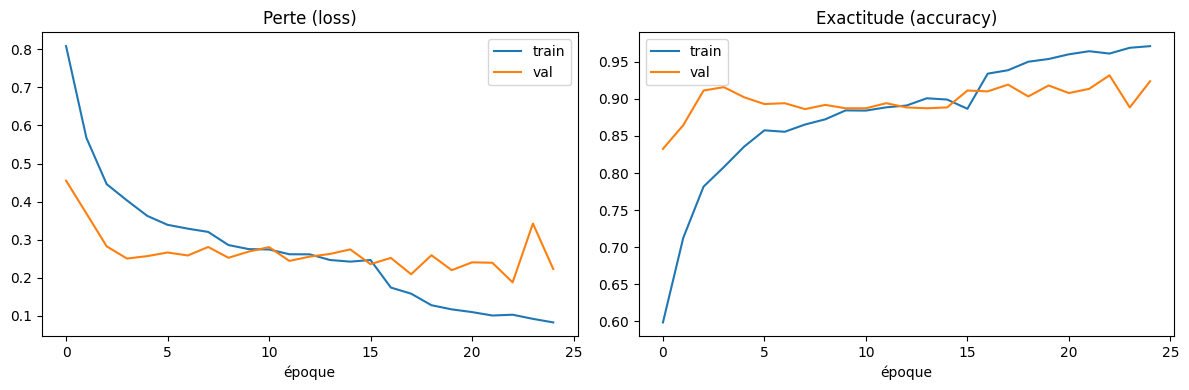

In [8]:
def cat(hs, k):
    out=[]; [out.extend(h.history.get(k,[])) for h in hs]; return out
hs=[h1,h2]
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(cat(hs,"loss"), label="train"); ax[0].plot(cat(hs,"val_loss"), label="val")
ax[0].set_title("Perte (loss)"); ax[0].set_xlabel("époque"); ax[0].legend()
ax[1].plot(cat(hs,"accuracy"), label="train"); ax[1].plot(cat(hs,"val_accuracy"), label="val")
ax[1].set_title("Exactitude (accuracy)"); ax[1].set_xlabel("époque"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig1_courbe_apprentissage.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Évaluation sur le jeu de test + metrics.json

In [9]:
y_true = test.classes
y_prob = model.predict(test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
accuracy    = (tp+tn)/(tp+tn+fp+fn)
sensibilite = tp/(tp+fn)          # recall / rappel
specificite = tn/(tn+fp)
precision   = tp/(tp+fp)
f1          = 2*precision*sensibilite/(precision+sensibilite)
fpr, tpr, _ = roc_curve(y_true, y_prob); auc_val = auc(fpr, tpr)

metrics = {"accuracy":round(float(accuracy),4),
           "sensibilite_recall":round(float(sensibilite),4),
           "specificite":round(float(specificite),4),
           "precision":round(float(precision),4),
           "f1":round(float(f1),4),
           "auc_roc":round(float(auc_val),4),
           "confusion_matrix":{"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}}
with open("metrics.json","w") as f: json.dump(metrics, f, indent=2, ensure_ascii=False)
print(json.dumps(metrics, indent=2, ensure_ascii=False))
print("\n>>> Reportez ces valeurs dans le tableau 3.3 du mémoire <<<")

28/28 ━━━━━━━━━━━━━━━━━━━━ 18s 491ms/step
{
  "accuracy": 0.9352,
  "sensibilite_recall": 0.9142,
  "specificite": 0.9916,
  "precision": 0.9966,
  "f1": 0.9536,
  "auc_roc": 0.9925,
  "confusion_matrix": {
    "TN": 236,
    "FP": 2,
    "FN": 55,
    "TP": 586
  }
}

>>> Reportez ces valeurs dans le tableau 3.3 du mémoire <<<


## 8. Matrice de confusion (Figure)

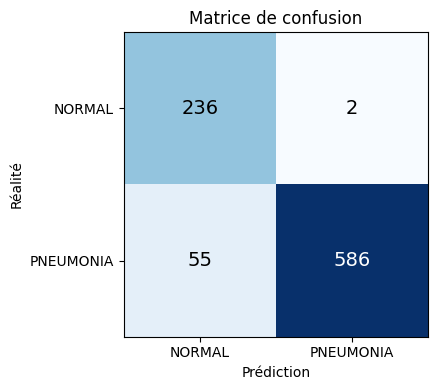

In [10]:
fig, ax = plt.subplots(figsize=(5,4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité"); ax.set_title("Matrice de confusion")
for i in range(2):
    for j in range(2):
        ax.text(j,i,cm[i,j],ha="center",va="center",
                color="white" if cm[i,j]>cm.max()/2 else "black", fontsize=14)
plt.tight_layout(); plt.savefig("fig2_matrice_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Courbe ROC (Figure)

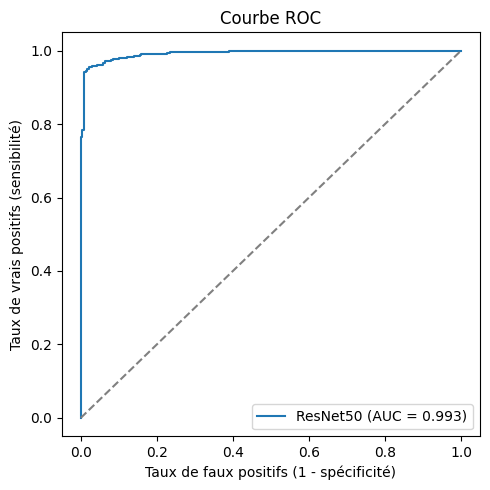

In [11]:
plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label=f"ResNet50 (AUC = {auc_val:.3f})")
plt.plot([0,1],[0,1],"--",color="grey")
plt.xlabel("Taux de faux positifs (1 - spécificité)")
plt.ylabel("Taux de vrais positifs (sensibilité)")
plt.title("Courbe ROC"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("fig3_courbe_roc.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Grad-CAM (explicabilité)
Vérifie que le modèle se concentre sur les zones pulmonaires pertinentes (garantie humaine, anti shortcut-learning).

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


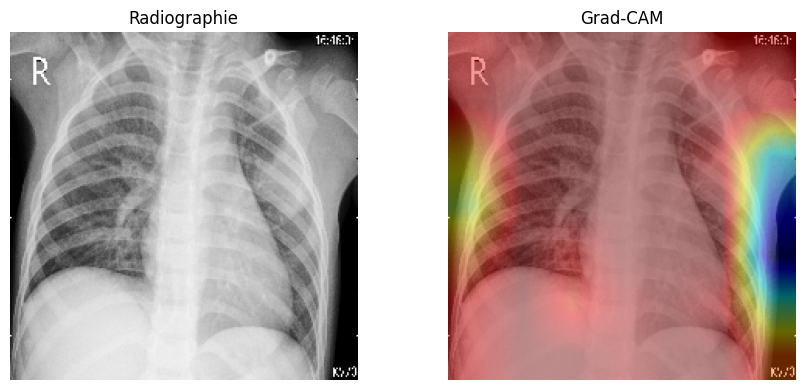

In [12]:
import cv2
def grad_cam(model, img_array, last_conv_layer_name="conv5_block3_out"):
    base_resnet = model.get_layer("resnet50")
    grad_model = tf.keras.models.Model(
        [base_resnet.inputs],
        [base_resnet.get_layer(last_conv_layer_name).output, base_resnet.output])
    # reconstruire la tête manuellement
    with tf.GradientTape() as tape:
        conv_out, base_out = grad_model(img_array)
        x = tf.reduce_mean(base_out, axis=(1,2))
        x = model.layers[-1](x)  # dense sigmoid
        loss = x[:,0]
    grads = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0,1,2))
    conv_out = conv_out[0]
    heatmap = tf.reduce_sum(conv_out * pooled, axis=-1)
    heatmap = tf.maximum(heatmap,0)/ (tf.reduce_max(heatmap)+1e-8)
    return heatmap.numpy()

# Exemple sur une image pathologique du test
import glob as _g
sample = _g.glob(os.path.join(WORK,"test","PNEUMONIA","*"))[0]
raw = tf.keras.preprocessing.image.load_img(sample, target_size=(IMG,IMG))
arr = tf.keras.preprocessing.image.img_to_array(raw)
inp = preprocess_input(np.expand_dims(arr.copy(),0))
try:
    hm = grad_cam(model, inp)
    hm = cv2.resize(hm,(IMG,IMG)); hm = np.uint8(255*hm)
    hm_color = cv2.applyColorMap(hm, cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(arr.astype(np.uint8),0.6, hm_color,0.4,0)
    fig,ax=plt.subplots(1,2,figsize=(9,4))
    ax[0].imshow(raw); ax[0].set_title("Radiographie"); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title("Grad-CAM"); ax[1].axis("off")
    plt.tight_layout(); plt.savefig("fig4_gradcam.png", dpi=150, bbox_inches="tight"); plt.show()
except Exception as e:
    print("Grad-CAM : ajustez 'last_conv_layer_name' si erreur.", e)

## 11. Récapitulatif des fichiers générés
- `metrics.json` → chiffres du **tableau 3.3**
- `fig1_courbe_apprentissage.png`
- `fig2_matrice_confusion.png`
- `fig3_courbe_roc.png`
- `fig4_gradcam.png`

Téléchargez-les (panneau Fichiers de Colab) et insérez-les dans le mémoire.

> **Rappel d'intégrité :** ces résultats sont les vôtres. Commentez-les avec votre propre analyse clinique (sensibilité vs spécificité, sur-apprentissage résiduel, pertinence des zones Grad-CAM).

## 9. Save the trained model (for the demo app)
Run this cell, then download `pneumonia_resnet50.keras` and put it in `demo/`.

In [ ]:
model.save('pneumonia_resnet50.keras')
from google.colab import files
files.download('pneumonia_resnet50.keras')